# Estimación de esfuerzo de software con SEERA
## Estudio del Grupo 1
El escenario principal utiliza siete atributos: tipo, dominio, esfuerzo estimado, tamaño, complejidad, experiencia en el lenguaje y metodología. El complementario excluye solo el esfuerzo estimado y utiliza seis. Se comparan regresión lineal, árbol y KNN sobre organizaciones reservadas. El objetivo es Actual effort en horas-persona.

El estudio es retrospectivo y descriptivo. Incluye auditoría, preparación dentro del entrenamiento, evaluación externa, sensibilidad individual de los siete atributos y consulta del modelo guardado. Los conjuntos reducidos de tres y dos entradas son controles auxiliares; no definen la hipótesis del escenario principal.

## 1 Cómo ejecutar y experimentar
Extrae la carpeta completa. Instala Python 3.12, crea un entorno e instala requirements.txt. Abre el cuaderno en Jupyter o VS Code, selecciona el kernel y ejecuta Restart Kernel → Run All. El Excel se busca en data/raw; cambia DATASET_PATH si utilizas otra ubicación. Cada ejecución crea su propia carpeta de salidas.

Los hiperparámetros se eligen dentro del entrenamiento; las reservas externas no seleccionan atributos ni configuraciones. La lista de siete variables responde a criterios conceptuales y de calidad de datos, sin optimalidad estadística demostrada.

In [1]:
from pathlib import Path
from datetime import datetime, timezone
import json, hashlib, platform, time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image

BASE=Path.cwd()
DATASET_PATH=BASE/'data/raw/SEERA cost estimation dataset.xlsx'
if not DATASET_PATH.exists(): DATASET_PATH=BASE/'SEERA cost estimation dataset.xlsx'
STRICT_SOURCE=True  # Verifica el Excel exacto del informe. No lo desactives para ocultar un archivo incorrecto.
RUN_ID='ejecucion_'+datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S%fZ')
OUT=BASE/'outputs'/RUN_ID
OUT.mkdir(parents=True,exist_ok=True)
print('Excel:',DATASET_PATH.resolve())
print('Salidas:',OUT.resolve())

Excel: /workspace/scratch/666c7f065513/autonomo_trabajo/SEERA_Entrega_Final_Grupo1/data/raw/SEERA cost estimation dataset.xlsx
Salidas: /workspace/scratch/666c7f065513/autonomo_trabajo/SEERA_Entrega_Final_Grupo1/outputs/ejecucion_20261112T210511101191Z


## 2 Funciones del protocolo
Esta celda define la lectura, las particiones, la preparación, los tres modelos y la selección interna. Está separada de su ejecución para poder revisar y modificar el código.

Cada organización se asigna completa a un bloque. La imputación y la estandarización se aprenden nuevamente en cada entrenamiento interno y externo. El esfuerzo real no entra al predictor. `ProjID` ordena empates de vecinos; `Organization id` agrupa, pero ninguno se usa como entrada.

In [2]:
"""Experimento final reproducible de 3 y 7 entradas en SEERA 1.3.

Selección por contenido y auditoría de entradas, no por correlaciones con y.
No busca un subconjunto óptimo mirando las reservas externas.
"""
from pathlib import Path
from itertools import product
import hashlib
import json
import platform
import time
import numpy as np
import pandas as pd
import sklearn
from sklearn.tree import DecisionTreeRegressor

ROOT = Path.cwd()
RAW = ROOT / 'data/raw/SEERA cost estimation dataset.xlsx'
ID, ORG, Y, E = 'ProjID', 'Organization id', 'Actual effort', 'Estimated effort'
TYPE, DOMAIN, METHOD = 'Development type', 'Application domain', 'Methodology'
SIZE, COMPLEXITY = 'Object points', 'Product complexity'
EXPERIENCE = 'Programmers experience in programming language'
SHA256 = 'e4d22e7e8f9f7e2452f8e97500082e3c1ec7c7c087a7ad70a191c3c5fe79f225'
CODES = {TYPE: [1,2,3,4], DOMAIN: [1,2,3,5,6,7], METHOD: [1,2,3,4,6,7]}
NEW = [SIZE, COMPLEXITY, EXPERIENCE, METHOD]
FEATURES_7 = [TYPE, DOMAIN, E] + NEW
SELECTION = {
    'entradas_principal': FEATURES_7,
    'entradas_complementario': [c for c in FEATURES_7 if c != E],
    'criterio': 'Cobertura de tamaño, dificultad, experiencia técnica y proceso; verificación del diccionario y ausencias. No selección por y.',
    'no_optimo_estadistico_demostrado': True,
    'codificacion_ordinal': {COMPLEXITY:'1 a 4, dificultad creciente', EXPERIENCE:'1 a 5, experiencia decreciente; códigos, no años'},
    'limitacion_ordinal': 'Se usan puntuaciones ordinales; la separación uniforme entre niveles es un supuesto, no una medida física. Evaluar codificación nominal como sensibilidad futura.',
    'K':5, 'K_interno':3, 'semilla_arbol':2026,
}
GRIDS = {
    'lineal':[{}],
    'arbol':[dict(max_depth=d,min_samples_leaf=l) for d,l in product([2,3,4,5,None],[2,5,10])],
    'knn':[dict(q=q,weights=w) for q,w in product([3,5,7,9],['uniform','distance'])],
}

def load_data(path=None, strict=True):
    path=Path(path or RAW)
    if not path.is_file():
        raise FileNotFoundError(f"No se encontró el Excel: {path.resolve()}")
    if strict and hashlib.sha256(path.read_bytes()).hexdigest()!=SHA256:
        raise ValueError("El Excel difiere de la fuente del informe. Revise el archivo o desactive strict conscientemente.")
    raw = pd.read_excel(path, sheet_name='SEERA dataset', header=1, keep_default_na=False)
    raw.columns = raw.columns.str.strip()
    data = raw[[ID,ORG,Y]+FEATURES_7].apply(pd.to_numeric, errors='coerce')
    assert data[ID].is_unique and data[ID].notna().all()
    if strict: assert len(data)==120 and data[ORG].nunique()==42
    for c in [SIZE, COMPLEXITY, EXPERIENCE]:
        invalid=data[c].isna() & ~raw[c].isin(['?', ''])
        if invalid.any(): raise ValueError(f"Valor no numérico no reconocido en {c}")
    assert data[[ID,ORG,Y,E,TYPE,DOMAIN,METHOD]].notna().all().all()
    assert (data[Y]>0).all() and (data[E]>=0).all()
    for c,levels in CODES.items(): assert data[c].isin(levels).all()
    for c,levels in [(COMPLEXITY,[1,2,3,4]),(EXPERIENCE,[1,2,3,4,5])]:
        assert data[c].dropna().isin(levels).all()
    assert (data[SIZE].dropna()>=0).all()
    return raw, data.sort_values(ID).reset_index(drop=True)

def blocks(data,k):
    sizes=data.groupby(ORG).size().reset_index(name='n').sort_values(['n',ORG],ascending=[False,True])
    loads=[0]*k; mapping={}
    for o,n in sizes.itertuples(index=False,name=None):
        b=min(range(k),key=lambda j:(loads[j],j)); mapping[o]=b; loads[b]+=n
    b=data[ORG].map(mapping).to_numpy()
    splits=[]
    for j in range(k):
        tr,te=np.flatnonzero(b!=j),np.flatnonzero(b==j)
        assert len(tr) and len(te) and set(data.iloc[tr][ORG]).isdisjoint(data.iloc[te][ORG])
        splits.append((tr,te))
    return splits,b

class Preparation:
    def fit(self,data,family,pack,with_e):
        self.family,self.pack,self.with_e=family,pack,with_e
        self.cat=[TYPE,DOMAIN]+([METHOD] if pack==7 else [])
        self.newnum=[SIZE,COMPLEXITY,EXPERIENCE] if pack==7 else []
        self.num=([E] if with_e else [])+self.newnum
        self.fill={}
        for c in self.newnum:
            observed=data[c].dropna()
            assert len(observed)>0
            self.fill[c]=float(observed.median() if c==SIZE else observed.mode().min())
        self.means={c:float(data[c].fillna(self.fill.get(c,0)).mean()) for c in self.num}
        self.stds={c:float(data[c].fillna(self.fill.get(c,0)).std(ddof=0)) for c in self.num}
        self.names=[f'{c}={v}' for c in self.cat for v in CODES[c] if not(family=='lineal' and v==1)]
        self.names+=self.num+[f'{c}:ausente' for c in self.newnum]
        self.seen={c:sorted(data[c].unique().tolist()) for c in self.cat}
        return self

    def transform(self,data):
        parts=[]
        for c in self.cat:
            assert data[c].isin(CODES[c]).all()
            parts.extend((data[c].to_numpy()==v).astype(float) for v in CODES[c] if not(self.family=='lineal' and v==1))
        for c in self.num:
            vals=data[c].fillna(self.fill.get(c,0)).to_numpy(float)
            if self.family=='knn':
                sd=self.stds[c]; vals=(vals-self.means[c])/sd if sd>0 else np.zeros(len(vals))
            parts.append(vals)
        parts.extend(data[c].isna().to_numpy(float) for c in self.newnum)
        out=np.column_stack(parts)
        assert np.isfinite(out).all() and out.shape[1]==len(self.names)
        return out

def fit_predict(train,test,family,pack,with_e,params):
    prep=Preparation().fit(train,family,pack,with_e)
    x,z=prep.transform(train),prep.transform(test)
    y=train[Y].to_numpy(float)
    if family=='lineal':
        beta,_,rank,_=np.linalg.lstsq(np.column_stack([np.ones(len(x)),x]),y,rcond=None)
        pred=np.column_stack([np.ones(len(z)),z])@beta
    elif family=='arbol':
        model=DecisionTreeRegressor(criterion='squared_error',random_state=2026,**params).fit(x,y)
        pred=model.predict(z); rank=None
    else:
        assert params['q']<=len(train)
        ids=train[ID].to_numpy(int); pred=[]
        for row in z:
            d=np.sqrt(((x-row)**2).sum(axis=1))
            chosen=np.lexsort((ids,d))[:params['q']]
            ds,ys=d[chosen],y[chosen]
            if (ds==0).any(): val=ys[ds==0].mean()
            elif params['weights']=='uniform': val=ys.mean()
            else: val=np.average(ys,weights=1/ds)
            pred.append(val)
        pred=np.asarray(pred); rank=None
    assert np.isfinite(pred).all()
    return np.maximum(0,pred), {'columnas_transformadas':len(prep.names),'rango_lineal':int(rank) if rank is not None else None,
        'imputacion':prep.fill,'medias':prep.means,'desviaciones':prep.stds,
        'categorias_validas_no_vistas':{c:sorted(set(test[c])-set(prep.seen[c])) for c in prep.cat}}

def tie(family,p):
    if family=='arbol': return (float('inf') if p['max_depth'] is None else p['max_depth'],-p['min_samples_leaf'])
    if family=='knn': return (-p['q'],0 if p['weights']=='uniform' else 1)
    return (0,)

def metrics(y,p):
    y,p=np.asarray(y,float),np.asarray(p,float)
    den=((y-y.mean())**2).sum()
    return dict(MAE=float(np.abs(y-p).mean()),RMSE=float(np.sqrt(((y-p)**2).mean())),R2=float(1-((y-p)**2).sum()/den) if den else None)

def run(data,out=None):
    out=Path(out or ROOT/'outputs'); out.mkdir(exist_ok=True,parents=True)
    # Se definen los conjuntos de predictores antes de calcular resultados.
    (out/'seleccion_predefinida.json').write_text(json.dumps(SELECTION,ensure_ascii=False,indent=2))
    start=time.perf_counter(); outer,labels=blocks(data,5)
    data[[ID,ORG]].assign(bloque=labels+1).to_csv(out/'particiones_externas.csv',index=False)
    preds=[]; logs=[]; inner_records=[]
    for b,(ri,ti) in enumerate(outer,1):
        train,test=data.iloc[ri].reset_index(drop=True),data.iloc[ti].reset_index(drop=True)
        inner,ilabels=blocks(train,3)
        inner_records.append(train[[ID,ORG]].assign(externo=b,interno=ilabels+1))
        for model,values in [('B1',test[E].to_numpy()),('B2',np.full(len(test),train[Y].median()))]:
            for j,p in enumerate(values):
                preds.append(dict(ProjID=int(test.iloc[j][ID]),organizacion=int(test.iloc[j][ORG]),bloque=b,entradas=0,escenario='referencia',modelo=model,y=float(test.iloc[j][Y]),prediccion=float(p)))
        for pack,with_e,family in product([3,7],[True,False],['lineal','arbol','knn']):
            model_start=time.perf_counter()
            candidates=[]
            for params in GRIDS[family]:
                errors=[]
                for a,v in inner:
                    p,_=fit_predict(train.iloc[a],train.iloc[v],family,pack,with_e,params)
                    errors.extend(np.abs(train.iloc[v][Y].to_numpy()-p))
                candidates.append((float(np.mean(errors)),params))
            score,params=min(candidates,key=lambda t:(t[0],tie(family,t[1])))
            p,diagnostics=fit_predict(train,test,family,pack,with_e,params)
            logs.append(dict(bloque=b,entradas=pack if with_e else pack-1,paquete=pack,con_e=with_e,modelo=family,
                             MAE_interno=score,parametros=params,segundos=time.perf_counter()-model_start,candidatos=[{'MAE_interno':s,'parametros':q} for s,q in candidates],**diagnostics))
            for j,value in enumerate(p):
                preds.append(dict(ProjID=int(test.iloc[j][ID]),organizacion=int(test.iloc[j][ORG]),bloque=b,entradas=pack if with_e else pack-1,
                    escenario='con_e' if with_e else 'sin_e',modelo=family,y=float(test.iloc[j][Y]),prediccion=float(value)))
        print(f'Bloque {b}/5 completado',flush=True)
    pred=pd.DataFrame(preds)
    pred['error_absoluto']=(pred.y-pred.prediccion).abs()
    rows=[]; foldrows=[]
    for (n,s,f),g in pred.groupby(['entradas','escenario','modelo'],sort=False):
        assert len(g)==len(data) and g.ProjID.is_unique
        rows.append(dict(entradas=n,escenario=s,modelo=f,**metrics(g.y,g.prediccion)))
        for b,h in g.groupby('bloque'):
            foldrows.append(dict(entradas=n,escenario=s,modelo=f,bloque=int(b),**metrics(h.y,h.prediccion)))
    summary=pd.DataFrame(rows)
    pred.to_csv(out/'predicciones_externas.csv',index=False)
    summary.to_csv(out/'metricas.csv',index=False)
    pd.DataFrame(foldrows).to_csv(out/'metricas_por_bloque.csv',index=False)
    pd.concat(inner_records).to_csv(out/'particiones_internas.csv',index=False)
    (out/'configuraciones.json').write_text(json.dumps(logs,ensure_ascii=False,indent=2))
    audit={'filas':len(data),'organizaciones':int(data[ORG].nunique()),'sha256_fuente_publicada':SHA256,
        'ausencias':{c:int(data[c].isna().sum()) for c in NEW},'proyectos_con_ausencias':int(data[NEW].isna().any(axis=1).sum()),
        'dimension_nominal_bruta':7,'variables_finales_no_es_optimo_garantizado':True,
        'plataforma':platform.platform(),'procesador':platform.processor(),'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__,
        'segundos':time.perf_counter()-start,'errores':0,
        'interpretacion':'Evaluación descriptiva retrospectiva. El conjunto de siete atributos responde a criterios de contenido; no demuestra que sea el subconjunto óptimo ni utilidad temprana.'}
    (out/'auditoria.json').write_text(json.dumps(audit,ensure_ascii=False,indent=2))
    return summary,pred,audit


def fit_saved(data, family, pack, with_e, params):
    """Ajusta un predictor. Guarda preparación y parámetros, sin evaluar en entrenamiento."""
    prep=Preparation().fit(data, family, pack, with_e)
    x=prep.transform(data)
    y=data[Y].to_numpy(float)
    payload={'family':family,'pack':pack,'with_e':with_e,'params':params,
             'preparation':prep.__dict__,'n_train':len(data)}
    if family=='lineal':
        beta,_,rank,_=np.linalg.lstsq(np.column_stack([np.ones(len(x)),x]),y,rcond=None)
        payload.update(beta=beta,rank=int(rank))
    elif family=='arbol':
        payload['tree']=DecisionTreeRegressor(criterion='squared_error',random_state=2026,**params).fit(x,y)
    else:
        payload.update(x_train=x,y_train=y,ids_train=data[ID].to_numpy(int))
    return payload

def predict_saved(payload, data):
    prep=Preparation()
    prep.__dict__.update(payload['preparation'])
    z=prep.transform(data)
    if payload['family']=='lineal':
        pred=np.column_stack([np.ones(len(z)),z])@payload['beta']
    elif payload['family']=='arbol':
        pred=payload['tree'].predict(z)
    else:
        pred=[]
        for row in z:
            ds=np.sqrt(((payload['x_train']-row)**2).sum(axis=1))
            chosen=np.lexsort((payload['ids_train'],ds))[:payload['params']['q']]
            d,y=ds[chosen],payload['y_train'][chosen]
            value=y[d==0].mean() if (d==0).any() else (
                y.mean() if payload['params']['weights']=='uniform' else np.average(y,weights=1/d))
            pred.append(value)
        pred=np.array(pred)
    assert np.isfinite(pred).all()
    return np.maximum(0,pred)

def select_and_refit(data, summary, out):
    """La selección de familia usa los MAE externos: su optimismo se declara en el informe."""
    ranking=summary.query("entradas==7 and escenario=='con_e'").copy()
    ranking['orden']=ranking.modelo.map({'lineal':0,'arbol':1,'knn':2})
    family=ranking.sort_values(['MAE','orden']).iloc[0].modelo
    inner,labels=blocks(data,3)
    candidates=[]
    for params in GRIDS[family]:
        errors=[]
        for tr,te in inner:
            p,_=fit_predict(data.iloc[tr],data.iloc[te],family,7,True,params)
            errors.extend(np.abs(data.iloc[te][Y].to_numpy()-p))
        candidates.append((float(np.mean(errors)),params))
    score,params=min(candidates,key=lambda t:(t[0],tie(family,t[1])))
    payload=fit_saved(data,family,7,True,params)
    import joblib
    joblib.dump(payload,Path(out)/'modelo_ampliado.joblib')
    meta={'familia':family,'entradas':FEATURES_7,'n_entrenamiento':len(data),
          'parametros':params,'MAE_seleccion_interna_reajuste':score,
          'advertencia':'El MAE interno del reajuste no es una nueva prueba externa. La familia se eligió mirando resultados externos.'}
    if family=='lineal':
        portable={**meta,'preparacion':payload['preparation'],'beta':payload['beta'].tolist(),'rango':payload['rank']}
        (Path(out)/'modelo_lineal_portable.json').write_text(json.dumps(portable,ensure_ascii=False,indent=2))
    data[[ID,ORG]].assign(bloque_reajuste=labels+1).to_csv(Path(out)/'particiones_reajuste.csv',index=False)
    (Path(out)/'modelo_metadata.json').write_text(json.dumps(meta,ensure_ascii=False,indent=2))
    return payload,meta

def consultar(payload, tipo, dominio, esfuerzo_estimado, object_points, complejidad,
              experiencia_lenguaje, metodologia, permitir_ausencias=False):
    """Recibe siete entradas. La discrepancia frente a e no es un error observado."""
    values={TYPE:tipo,DOMAIN:dominio,E:esfuerzo_estimado,SIZE:object_points,
            COMPLEXITY:complejidad,EXPERIENCE:experiencia_lenguaje,METHOD:metodologia}
    warnings=[]
    for c,v in values.items():
        if v is None:
            if c in [SIZE,COMPLEXITY,EXPERIENCE] and permitir_ausencias:
                warnings.append(f'{c}: se aplicará la imputación del entrenamiento')
                values[c]=np.nan
                continue
            raise ValueError(f'Falta {c}')
        if isinstance(v,bool) or not isinstance(v,(int,float,np.number)) or not np.isfinite(v):
            raise ValueError(f'{c}: debe ser numérico y finito')
        if c in CODES and v not in CODES[c]: raise ValueError(f'Código inválido en {c}')
        if c in [E,SIZE] and v<0: raise ValueError(f'{c}: no puede ser negativo')
        if c==COMPLEXITY and v not in [1,2,3,4]: raise ValueError('Complejidad debe estar entre 1 y 4')
        if c==EXPERIENCE and v not in [1,2,3,4,5]: raise ValueError('Experiencia debe estar entre 1 y 5')
        if c in [E,SIZE] and v>payload['rangos_observados'][c][1]:
            warnings.append(f'{c}: superior al máximo observado; posible extrapolación')
    for c in [TYPE,DOMAIN,METHOD]:
        if values[c] not in payload['preparation']['seen'][c]:warnings.append(f'{c}: categoría válida sin ejemplos en entrenamiento')
    yhat=float(predict_saved(payload,pd.DataFrame([values]))[0])
    return {'horas_persona_predichas':yhat,
            'diferencia_firmada_frente_a_e':yhat-esfuerzo_estimado,
            'discrepancia_absoluta_frente_a_e':abs(yhat-esfuerzo_estimado),
            'discrepancia_porcentual_frente_a_e':100*abs(yhat-esfuerzo_estimado)/esfuerzo_estimado if esfuerzo_estimado>0 else None,
            'avisos':warnings}


## 3 Configuración del experimento
Se utilizan cinco bloques externos y tres internos por organización, con semilla 2026. q indica número de vecinos; weights, promedio uniforme o inverso a distancia. max_depth limita profundidad y min_samples_leaf controla el mínimo por hoja; None representa profundidad sin límite. Las cifras del informe corresponden a las rejillas definidas aquí.

In [3]:
GRIDS={
 'lineal':[{}],
 'arbol':[{'max_depth':d,'min_samples_leaf':l}
          for d in [2,3,4,5,None] for l in [2,5,10]],
 'knn':[{'q':q,'weights':w}
        for q in [3,5,7,9] for w in ['uniform','distance']]
}
(OUT/'configuracion_ejecucion.json').write_text(json.dumps({'seleccion':SELECTION,'rejillas':GRIDS},ensure_ascii=False,indent=2))
print({family:len(grid) for family,grid in GRIDS.items()})

{'lineal': 1, 'arbol': 15, 'knn': 8}


## 4 Lectura y auditoría
Cada fila de SEERA es un proyecto; los encabezados están en la segunda fila del Excel. Los marcadores ? y N/A se distinguen de cero. Se verifican los siete atributos, el objetivo y los identificadores. Tipo, dominio y metodología son nominales; esfuerzo estimado y tamaño son cuantitativos; complejidad y experiencia son ordinales. Object points equivale a pantallas más reportes; las escalas ordinales son códigos, no medidas físicas.

In [4]:
raw,data=load_data(DATASET_PATH,strict=STRICT_SOURCE)
ACTUAL_HASH=hashlib.sha256(DATASET_PATH.read_bytes()).hexdigest()
print(f'Filas={len(raw)}, columnas={raw.shape[1]}, organizaciones={data[ORG].nunique()}')
print('SHA-256:',ACTUAL_HASH)
assert raw.shape[1]==76
audit_inputs=pd.DataFrame([{'atributo':c,'ausentes':int(data[c].isna().sum()),
                           'porcentaje_ausente':100*data[c].isna().mean(),
                           'valores_distintos_observados':data[c].nunique()}
                          for c in FEATURES_7])
display(audit_inputs)
display(data[[ID,ORG]+FEATURES_7+[Y]].head())
display(data.loc[data[NEW].isna().any(axis=1),[ID]+NEW])
audit_inputs.to_csv(OUT/'auditoria_entradas.csv',index=False)

Filas=120, columnas=76, organizaciones=42
SHA-256: e4d22e7e8f9f7e2452f8e97500082e3c1ec7c7c087a7ad70a191c3c5fe79f225


,atributo,ausentes,porcentaje_ausente,valores_distintos_observados
0,Development type,0,0.000000,4
1,Application domain,0,0.000000,6
2,Estimated effort,0,0.000000,66
3,Object points,2,1.666667,84
4,Product complexity,3,2.500000,4
5,Programmers experience in programming language,1,0.833333,5
6,Methodology,0,0.000000,6


,ProjID,Organization id,Development type,Application domain,Estimated effort,Object points,Product complexity,Programmers experience in programming language,Methodology,Actual effort
0,1,1,1,7,2112,100.0,2.0,2.0,2,3168.0
1,2,25,1,3,1056,19.0,1.0,2.0,1,1584.0
2,3,2,1,3,3168,64.0,3.0,1.0,3,5280.0
3,4,42,1,7,5280,246.0,4.0,1.0,2,5280.0
4,5,42,1,7,19008,420.0,3.0,1.0,2,38016.0


,ProjID,Object points,Product complexity,Programmers experience in programming language,Methodology
10,11,NaN,1.0,1.0,3
29,30,70.0,NaN,1.0,1
32,33,511.0,NaN,4.0,1
69,70,NaN,NaN,NaN,2


## 5 Descripción de los datos
Estos resúmenes describen la muestra; no se usan para elegir atributos por correlación con el objetivo. Los valores extremos se conservan. `Actual effort` y `Estimated effort` comparten un factor derivado de equipo y jornada, según el documento de fórmulas incluido. Esa dependencia limita la interpretación de una buena precisión.

Experiencia está codificada de 1 (mayor experiencia) a 5 (primera experiencia en ese proyecto). Complejidad va de 1 a 4. Se emplean puntuaciones ordinales: no se interpretan como años ni intervalos físicos iguales. Metodología es nominal, por lo que se representa mediante indicadores.

Development type {1: 90, 2: 9, 3: 10, 4: 11}
Application domain {1: 14, 2: 34, 3: 6, 5: 18, 6: 10, 7: 38}
Methodology {1: 41, 2: 27, 3: 42, 4: 4, 6: 5, 7: 1}
Product complexity {1.0: 34, 2.0: 55, 3.0: 14, 4.0: 14, nan: 3}
Programmers experience in programming language {1.0: 51, 2.0: 33, 3.0: 21, 4.0: 8, 5.0: 6, nan: 1}


,Actual effort,Estimated effort,Object points
count,120.00,120.00,118.00
mean,9060.93,5225.18,203.47
std,12598.48,6881.11,250.81
min,396.00,176.00,7.00
25%,2112.00,1278.75,37.00
50%,4576.00,2860.00,93.00
75%,10032.00,6336.00,334.50
95%,33884.40,14924.80,650.00
max,79200.00,50688.00,1700.00


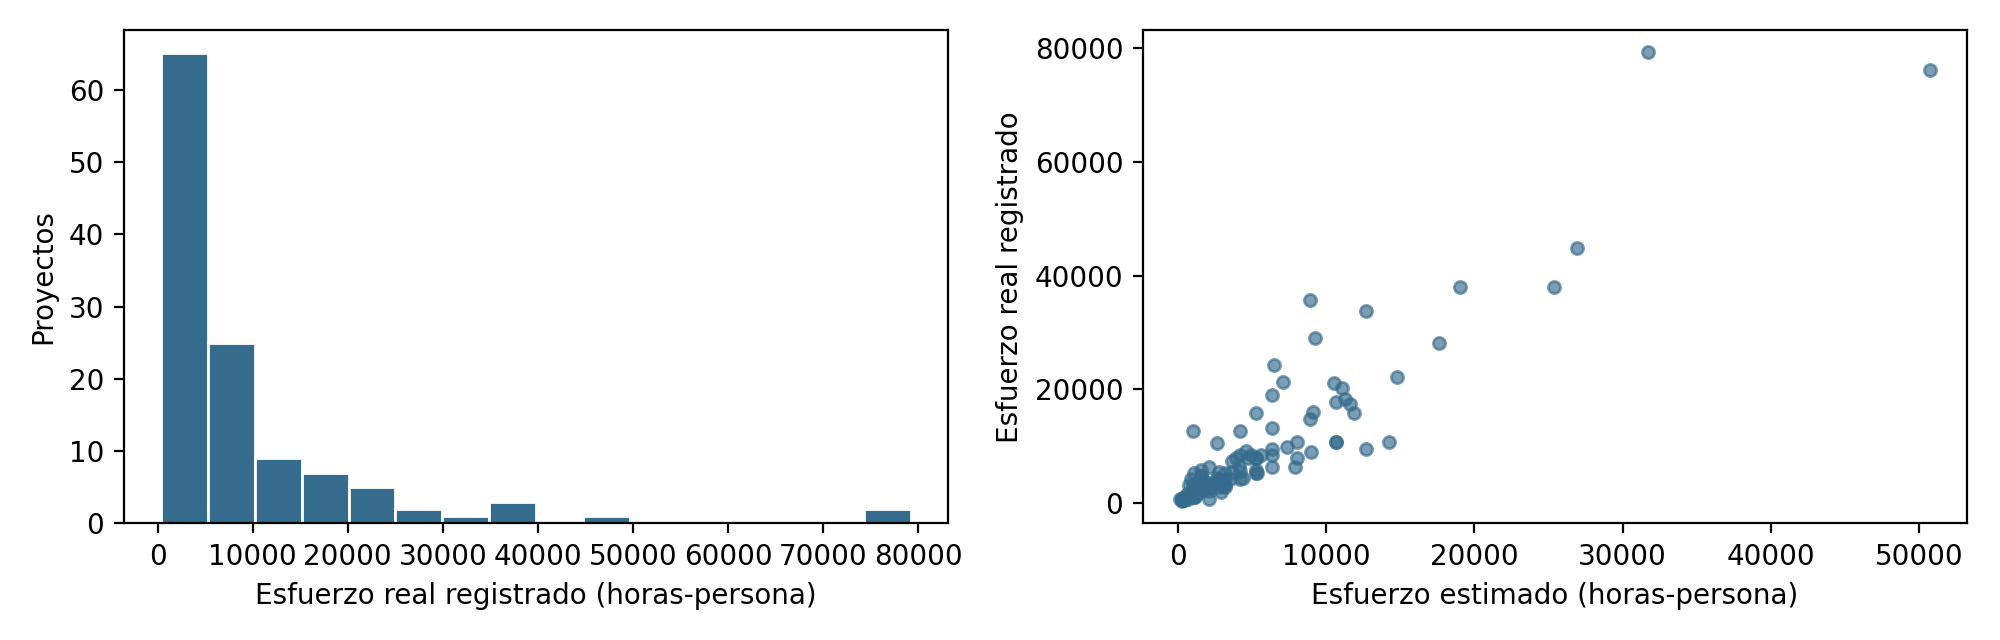

In [5]:
display(data[[Y,E,SIZE]].describe(percentiles=[.25,.5,.75,.95]).round(2))
for c in [TYPE,DOMAIN,METHOD,COMPLEXITY,EXPERIENCE]:
    print(c, data[c].value_counts(dropna=False).sort_index().to_dict())
fig,axes=plt.subplots(1,2,figsize=(10,3.2))
axes[0].hist(data[Y],bins=16,color='#356b8c',edgecolor='white')
axes[0].set(xlabel='Esfuerzo real registrado (horas-persona)',ylabel='Proyectos')
axes[1].scatter(data[E],data[Y],s=19,alpha=.65,color='#356b8c')
axes[1].set(xlabel='Esfuerzo estimado (horas-persona)',ylabel='Esfuerzo real registrado')
fig.tight_layout();fig.savefig(OUT/'descripcion_datos.png',dpi=200)
display(Image(filename=str(OUT/'descripcion_datos.png')));plt.close(fig)

## 6 Preparación y particiones sin fuga de información
Tamaño ausente se completa con la mediana del entrenamiento; complejidad y experiencia, con su moda (menor código ante empate). La representación incluye tres indicadores de ausencia. Tipo, dominio y metodología usan el vocabulario documentado; la regresión lineal omite una categoría por atributo e incluye intercepto.

Solo KNN estandariza las variables numéricas después de imputar: resta la media del entrenamiento y divide entre su desviación estándar poblacional. Si la desviación es cero, devuelve cero. Los indicadores permanecen en 0/1.

En la celda siguiente se muestra **un entrenamiento externo**, no una preparación ajustada sobre toda la muestra antes de validar.

In [6]:
outer,labels=blocks(data,5)
fold_sizes=[]
for b,(tr,te) in enumerate(outer,1):
    assert set(data.iloc[tr][ORG]).isdisjoint(data.iloc[te][ORG])
    inner,_=blocks(data.iloc[tr].reset_index(drop=True),3)
    fold_sizes.append({'bloque':b,'entrenamiento':len(tr),'reserva':len(te),
                       'organizaciones_reserva':data.iloc[te][ORG].nunique(),
                       'entrenamiento_interno':len(inner[0][0]),'reserva_interna':len(inner[0][1])})
display(pd.DataFrame(fold_sizes))
train_example=data.iloc[outer[0][0]]
prep_example=Preparation().fit(train_example,'knn',7,True)
print('Imputación aprendida en ese entrenamiento:',prep_example.fill)
print('Columnas transformadas KNN:',len(prep_example.names))
display(pd.DataFrame(prep_example.transform(train_example.head()),columns=prep_example.names).round(3))
pd.DataFrame(fold_sizes).to_csv(OUT/'tamanos_bloques.csv',index=False)

Imputación aprendida en ese entrenamiento: {'Object points': 88.0, 'Product complexity': 2.0, 'Programmers experience in programming language': 1.0}
Columnas transformadas KNN: 23


,bloque,entrenamiento,reserva,organizaciones_reserva,entrenamiento_interno,reserva_interna
0,1,96,24,7,64,32
1,2,96,24,8,64,32
2,3,96,24,8,64,32
3,4,96,24,9,64,32
4,5,96,24,10,64,32


,Development type=1,Development type=2,Development type=3,Development type=4,Application domain=1,Application domain=2,Application domain=3,Application domain=5,Application domain=6,Application domain=7,Methodology=1,Methodology=2,Methodology=3,Methodology=4,Methodology=6,Methodology=7,Estimated effort,Object points,Product complexity,Programmers experience in programming language,Object points:ausente,Product complexity:ausente,Programmers experience in programming language:ausente
0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,-0.415,-0.378,-0.065,0.045,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,-0.563,-0.688,-1.112,0.045,0.0,0.0,0.0
2,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,-0.266,-0.516,0.981,-0.825,0.0,0.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.030,0.179,2.028,-0.825,0.0,0.0,0.0
4,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.955,0.844,0.981,-0.825,0.0,0.0,0.0


## 7 Evaluación anidada
Cada entrenamiento externo selecciona parámetros por MAE interno reunido, reajusta preparación y predictor, y evalúa la reserva. El escenario principal de siete entradas y el complementario de seis comparten particiones. El cuaderno también calcula controles reducidos de tres/dos entradas como análisis auxiliar. B1 devuelve esfuerzo estimado; B2, mediana del objetivo en entrenamiento externo. Las salidas se recortan a cero.

In [7]:
summary,pred,audit=run(data,OUT)
audit['sha256_excel_ejecutado']=ACTUAL_HASH
audit['fuente_exacta_del_informe']=ACTUAL_HASH==SHA256
(OUT/'auditoria.json').write_text(json.dumps(audit,ensure_ascii=False,indent=2))
assert pred.groupby(['entradas','escenario','modelo']).size().eq(len(data)).all()
assert not pred.duplicated(['entradas','escenario','modelo','ProjID']).any()
print(f'Evaluación completada en {audit["segundos"]:.3f} segundos. No incluye carga ni gráficos.')
display(summary.round({'MAE':2,'RMSE':2,'R2':3}))

Bloque 1/5 completado
Bloque 2/5 completado
Bloque 3/5 completado
Bloque 4/5 completado
Bloque 5/5 completado
Evaluación completada en 2.832 segundos. No incluye carga ni gráficos.


,entradas,escenario,modelo,MAE,RMSE,R2
0,0,referencia,B1,4018.35,7815.75,0.612
1,0,referencia,B2,6915.29,13261.89,-0.117
2,3,con_e,lineal,3345.04,5386.42,0.816
3,3,con_e,arbol,4392.68,8366.10,0.555
4,3,con_e,knn,4777.98,9090.45,0.475
5,2,sin_e,lineal,8571.51,14380.71,-0.314
6,2,sin_e,arbol,7806.31,12605.28,-0.009
7,2,sin_e,knn,9722.65,16920.91,-0.819
8,7,con_e,lineal,4292.72,6848.25,0.702
9,7,con_e,arbol,4347.27,7572.35,0.636


## 8 Controles de cálculo y conjuntos reducidos
Se comprueba el cálculo con una tabla de referencia. Los conjuntos reducidos utilizan tipo y dominio, con o sin esfuerzo estimado. Son controles auxiliares del experimento; los resultados y la hipótesis del informe se refieren al conjunto principal de siete atributos y al complementario de seis. MAE y RMSE tienen unidades de horas-persona; R² no es porcentaje de acierto.

In [8]:
previous_path=BASE/'data/reference/metricas_originales_3_entradas.csv'
if previous_path.exists():
    previous=pd.read_csv(previous_path)
    print('Tabla de control disponible:',previous_path.name)
    display(previous)
    default_grids={'lineal':[{}], 'arbol':[{'max_depth':d,'min_samples_leaf':l} for d in [2,3,4,5,None] for l in [2,5,10]],
                   'knn':[{'q':q,'weights':w} for q in [3,5,7,9] for w in ['uniform','distance']]}
    if STRICT_SOURCE and GRIDS==default_grids:
        checks=[]
        for r in previous.itertuples(index=False):
            n={'principal':3,'complementario':2,'referencia':0}[r.escenario]
            current=summary[(summary.entradas==n)&(summary.modelo==r.modelo)].iloc[0]
            checks.append(max(abs(current[k]-getattr(r,k)) for k in ['MAE','RMSE','R2']))
        assert max(checks)<1e-5
        print('Reproducción verificada de los ocho procedimientos de control en MAE, RMSE y R²; diferencia máxima:',max(checks))
else:
    print('La tabla de control está en el paquete; su ausencia no impide ejecutar este cuaderno.')

comparison=[]
for model in ['lineal','arbol','knn']:
    for with_e in [True,False]:
        old=summary.query('modelo==@model and entradas==@n',local_dict={'n':3 if with_e else 2}).iloc[0]
        new=summary.query('modelo==@model and entradas==@n',local_dict={'n':7 if with_e else 6}).iloc[0]
        comparison.append({'escenario':'Con e' if with_e else 'Sin e','modelo':model,
                           'MAE_reducido':old.MAE,'MAE_completo':new.MAE,
                           'reduccion_porcentual_MAE':100*(old.MAE-new.MAE)/old.MAE})
comparison=pd.DataFrame(comparison)
comparison.to_csv(OUT/'comparacion_conjuntos.csv',index=False)
display(comparison.round(2))

Tabla de control disponible: metricas_originales_3_entradas.csv
Reproducción verificada de los ocho procedimientos de control en MAE, RMSE y R²; diferencia máxima: 3.637978807091713e-12


,escenario,modelo,n,MAE,RMSE,R2
0,complementario,arbol,120,7806.314016,12605.280250,-0.009492
1,complementario,knn,120,9722.647189,16920.914263,-0.819054
2,complementario,lineal,120,8571.509801,14380.714898,-0.313889
3,principal,arbol,120,4392.678067,8366.100109,0.555324
4,principal,knn,120,4777.983661,9090.454553,0.474988
5,principal,lineal,120,3345.036420,5386.419184,0.815669
6,referencia,B1,120,4018.345833,7815.753789,0.611904
7,referencia,B2,120,6915.287500,13261.888510,-0.117400


,escenario,modelo,MAE_reducido,MAE_completo,reduccion_porcentual_MAE
0,Con e,lineal,3345.04,4292.72,-28.33
1,Sin e,lineal,8571.51,8196.04,4.38
2,Con e,arbol,4392.68,4347.27,1.03
3,Sin e,arbol,7806.31,7105.26,8.98
4,Con e,knn,4777.98,5166.63,-8.13
5,Sin e,knn,9722.65,7226.49,25.67


## 9 Visualización del error
Se muestran el escenario principal de siete atributos y el complementario de seis, junto con B1 y B2 en los mismos proyectos. La comparación de errores es descriptiva.

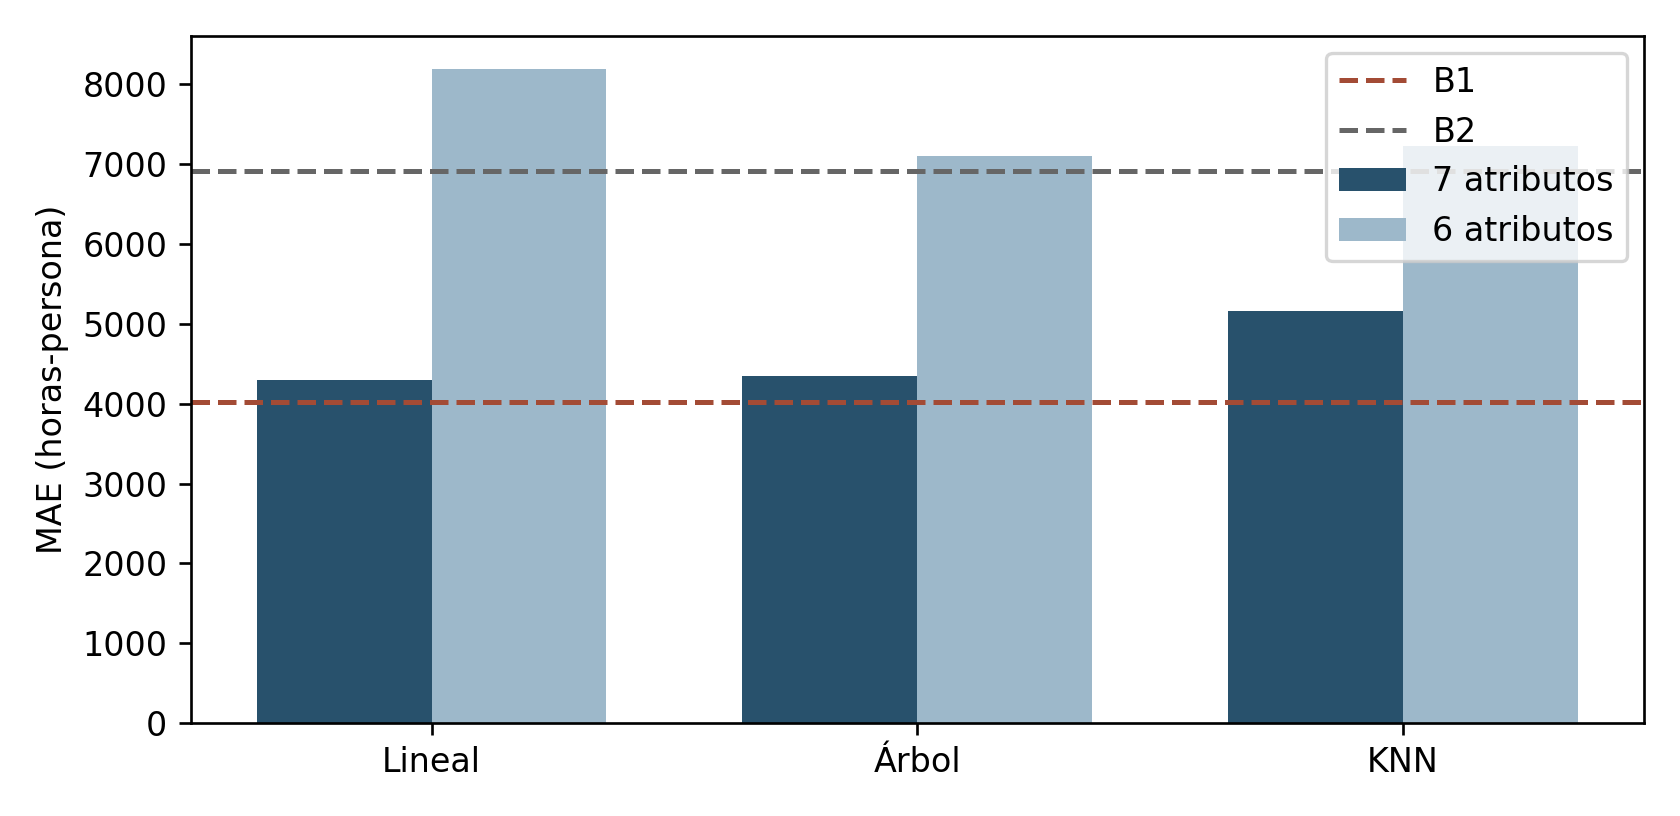

In [9]:
fig,ax=plt.subplots(figsize=(7,3.4))
names=['lineal','arbol','knn']; xx=np.arange(3)
for n,off,color in [(7,-.18,'#28516c'),(6,.18,'#9db8ca')]:
    vals=[summary.query('entradas==@n and modelo==@m').iloc[0].MAE for m in names]
    ax.bar(xx+off,vals,.36,label=f'{n} atributos',color=color)
for ref,color in [('B1','#a34b35'),('B2','#666666')]:
    ax.axhline(summary.query('modelo==@ref').iloc[0].MAE,color=color,ls='--',label=ref)
ax.set_xticks(xx,['Lineal','Árbol','KNN']);ax.set_ylabel('MAE (horas-persona)');ax.legend()
fig.tight_layout();fig.savefig(OUT/'comparacion_MAE.png',dpi=240)
display(Image(filename=str(OUT/'comparacion_MAE.png')));plt.close(fig)


## 10 Parámetros y costo de ejecución
Los CSV y JSON conservan las configuraciones candidatas y ganadoras por bloque. La diferencia entre el peor y el mejor MAE interno describe sensibilidad dentro de la rejilla, sin usar la reserva externa para ajustar. Los tiempos dependen del equipo y no son una garantía de rendimiento industrial.

In [10]:
logs=json.loads((OUT/'configuraciones.json').read_text())
params_table=pd.DataFrame([{'entradas':r['entradas'],'modelo':r['modelo'],'bloque':r['bloque'],
                            'parametros':str(r['parametros']),'MAE_interno':r['MAE_interno'],
                            'rango_MAE_candidatos':max(c['MAE_interno'] for c in r['candidatos'])-min(c['MAE_interno'] for c in r['candidatos']),
                            'segundos':r['segundos'],'rango_lineal':r['rango_lineal']}
                           for r in logs])
display(params_table.query('entradas in [7,6]').round(3))
display(params_table.groupby(['entradas','modelo']).segundos.sum().reset_index().round(4))
params_table.to_csv(OUT/'resumen_parametros.csv',index=False)
print('Entorno:',audit['python'],audit['numpy'],audit['pandas'],audit['sklearn'])

Entorno: 3.12.14 2.3.5 2.2.3 1.8.0


,entradas,modelo,bloque,parametros,MAE_interno,rango_MAE_candidatos,segundos,rango_lineal
6,7,lineal,1,{},3718.299,0.000,0.008,20.0
7,7,arbol,1,"{'max_depth': 3, 'min_samples_leaf': 2}",4909.076,636.623,0.113,NaN
8,7,knn,1,"{'q': 5, 'weights': 'distance'}",5249.462,241.838,0.062,NaN
9,6,lineal,1,{},7685.004,0.000,0.007,19.0
10,6,arbol,1,"{'max_depth': 2, 'min_samples_leaf': 5}",6942.952,1360.606,0.113,NaN
11,6,knn,1,"{'q': 5, 'weights': 'distance'}",6651.691,274.674,0.060,NaN
18,7,lineal,2,{},4831.972,0.000,0.008,20.0
19,7,arbol,2,"{'max_depth': 3, 'min_samples_leaf': 2}",4934.165,906.854,0.112,NaN
20,7,knn,2,"{'q': 7, 'weights': 'distance'}",6162.182,627.644,0.060,NaN
21,6,lineal,2,{},8554.094,0.000,0.007,19.0


,entradas,modelo,segundos
0,2,arbol,0.2659
1,2,knn,0.1339
2,2,lineal,0.0127
3,3,arbol,0.2999
4,3,knn,0.1653
5,3,lineal,0.0161
6,6,arbol,0.5424
7,6,knn,0.2897
8,6,lineal,0.0361
9,7,arbol,0.5739


## 11 Análisis de errores e hipótesis
Se cuenta en cuántos proyectos el lineal de siete atributos mejora o empeora respecto de B1 y se revisan sus errores por bloque. La hipótesis requiere que al menos una familia del escenario principal supere B1 en MAE externo; no se redefine según los controles reducidos.

In [11]:
a=pred.query("entradas==7 and modelo=='lineal'")
b=pred.query("modelo=='B1'")
paired=a[['ProjID','organizacion','bloque','y','prediccion','error_absoluto']].merge(
    b[['ProjID','error_absoluto']],on='ProjID',suffixes=('_lineal','_B1'),validate='one_to_one')
paired['mejora_horas']=paired.error_absoluto_B1-paired.error_absoluto_lineal
display(paired.groupby('bloque')[['error_absoluto_lineal','error_absoluto_B1','mejora_horas']].mean().round(2))
print('Proyectos: mejora=',(paired.mejora_horas>0).sum(),'empeora=',(paired.mejora_horas<0).sum(),'empata=',(paired.mejora_horas==0).sum())
display(paired.nlargest(5,'error_absoluto_lineal').round(2))
paired.to_csv(OUT/'errores_pareados_lineal7_B1.csv',index=False)
best7=summary.query("entradas==7").sort_values('MAE').iloc[0]
b1=summary.query("modelo=='B1'").iloc[0]
print('¿Algún modelo de siete entradas supera B1 en MAE?',bool(best7.MAE<b1.MAE))
print('Esta respuesta corresponde a esta ejecución; no se modifica la hipótesis para favorecerla.')

Proyectos: mejora= 49 empeora= 71 empata= 0
¿Algún modelo de siete entradas supera B1 en MAE? False
Esta respuesta corresponde a esta ejecución; no se modifica la hipótesis para favorecerla.


,error_absoluto_lineal,error_absoluto_B1,mejora_horas
bloque,,,
1,5235.76,4776.75,-459.01
2,2304.38,2169.29,-135.09
3,4966.05,7003.79,2037.74
4,3964.19,2342.31,-1621.88
5,4993.21,3799.58,-1193.62


,ProjID,organizacion,bloque,y,prediccion,error_absoluto_lineal,error_absoluto_B1,mejora_horas
104,11,4,5,35640.0,2563.07,33076.93,26730.0,-6346.93
67,95,7,3,79200.0,48304.53,30895.47,47520.0,16624.53
16,70,19,1,4224.0,31291.15,27067.15,1056.0,-26011.15
118,117,4,5,21384.0,4266.69,17117.31,14256.0,-2861.31
19,75,12,1,33792.0,19612.78,14179.22,21120.0,6940.78


## Sensibilidad de los siete atributos
Para cada familia se reutiliza el modelo ajustado en cada entrenamiento externo y su preparación. Se permuta cada columna cruda dentro de la reserva, incluidas sus ausencias, sin reajustar. Se repite 30 veces con semilla 2026 y se reúne el error de 120 proyectos. ΔMAE es el error perturbado menos el MAE sin perturbación. No se utiliza para elegir variables, familias ni hiperparámetros. Valores negativos o nulos no demuestran irrelevancia; las asociaciones entre atributos limitan la atribución.

In [12]:
from pathlib import Path
import json,time,sys
import numpy as np
import pandas as pd

def sensibilidad_atributos(data,out,repeticiones=30,semilla=2026):
    """Permutación en reservas; parámetros ya elegidos dentro del entrenamiento.

    La columna cruda se permuta junto con sus ausencias. La preparación se
    reutiliza sin reajustar; este análisis no selecciona variables ni parámetros.
    """
    out=Path(out);logs=json.loads((out/'configuraciones.json').read_text())
    guardadas=pd.read_csv(out/'predicciones_externas.csv')
    outer,_=blocks(data,5);rng=np.random.default_rng(semilla)
    errores={(f,c,r):0. for f in ['lineal','arbol','knn'] for c in FEATURES_7 for r in range(repeticiones)}
    bases={f:0. for f in ['lineal','arbol','knn']};start=time.perf_counter()
    for b,(tr,te) in enumerate(outer,1):
        train,test=data.iloc[tr].reset_index(drop=True),data.iloc[te].reset_index(drop=True)
        perms=[rng.permutation(len(test)) for _ in range(repeticiones)]
        for family in bases:
            log=next(x for x in logs if x['bloque']==b and x['entradas']==7 and x['modelo']==family)
            payload=fit_saved(train,family,7,True,log['parametros'])
            baseline=predict_saved(payload,test)
            expected=guardadas.query('entradas==7 and modelo==@family and bloque==@b').set_index('ProjID').loc[test[ID],'prediccion'].to_numpy()
            assert np.allclose(baseline,expected,atol=1e-6,rtol=1e-10)
            bases[family]+=float(np.abs(test[Y].to_numpy()-baseline).sum())
            for c in FEATURES_7:
                for r,perm in enumerate(perms):
                    pert=test.copy();pert[c]=test[c].to_numpy()[perm]
                    pred=predict_saved(payload,pert)
                    errores[family,c,r]+=float(np.abs(test[Y].to_numpy()-pred).sum())
    detailed=[];summary=[]
    for f in bases:
        base=bases[f]/len(data)
        for c in FEATURES_7:
            vals=np.array([errores[f,c,r]/len(data) for r in range(repeticiones)])
            for r,value in enumerate(vals):detailed.append({'modelo':f,'atributo':c,'repeticion':r+1,'MAE_base':base,'MAE_permutado':value,'delta_MAE':value-base})
            summary.append({'modelo':f,'atributo':c,'MAE_base':base,'delta_MAE_media':float((vals-base).mean()),'desviacion_repeticiones':float(vals.std(ddof=0)),'min_delta':float((vals-base).min()),'max_delta':float((vals-base).max())})
    detail=pd.DataFrame(detailed);summ=pd.DataFrame(summary)
    summ.to_csv(out/'sensibilidad_atributos.csv',index=False)
    detail.to_csv(out/'sensibilidad_atributos_repeticiones.csv',index=False)
    (out/'sensibilidad_atributos_config.json').write_text(json.dumps({'semilla':semilla,'repeticiones':repeticiones,'bloques_externos':5,'proyectos':len(data),'columnas_crudas':FEATURES_7,'seleccion_por_esta_prueba':False,'interpretacion':'Dependencia descriptiva del predictor ante perturbaciones. No causalidad ni aporte independiente; permutar rompe asociaciones entre variables.','segundos':time.perf_counter()-start},ensure_ascii=False,indent=2))
    return summ


sensibilidad=sensibilidad_atributos(data,OUT,repeticiones=30,semilla=2026)
display(sensibilidad.pivot(index='atributo',columns='modelo',values='delta_MAE_media').round(2))


modelo,arbol,knn,lineal
atributo,,,
Application domain,-52.40,165.28,171.62
Development type,100.47,31.49,-20.20
Estimated effort,5195.25,2469.22,5508.13
Methodology,0.00,168.08,-46.29
Object points,-41.47,296.38,269.32
Product complexity,0.00,-12.02,-38.22
Programmers experience in programming language,0.00,-91.56,-5.13


## 12 Reajuste del modelo para consulta
Se selecciona la familia con menor MAE externo entre las de siete atributos; desempate: lineal, árbol y KNN. Sus parámetros se revisan mediante tres bloques organizacionales y se reajusta con 120 proyectos. Elegir la familia a partir de las reservas puede producir optimismo; el reajuste no es otra prueba de generalización.

In [13]:
payload,model_meta=select_and_refit(data,summary,OUT)
payload['rangos_observados']={c:[float(data[c].min()),float(data[c].max())] for c in [E,SIZE]}
import joblib
joblib.dump(payload,OUT/'modelo_ampliado.joblib')
print(json.dumps(model_meta,ensure_ascii=False,indent=2))
print('Modelo guardado:',(OUT/'modelo_ampliado.joblib').name)

{
  "familia": "lineal",
  "entradas": [
    "Development type",
    "Application domain",
    "Estimated effort",
    "Object points",
    "Product complexity",
    "Programmers experience in programming language",
    "Methodology"
  ],
  "n_entrenamiento": 120,
  "parametros": {},
  "MAE_seleccion_interna_reajuste": 4520.580166998849,
  "advertencia": "El MAE interno del reajuste no es una nueva prueba externa. La familia se eligió mirando resultados externos."
}
Modelo guardado: modelo_ampliado.joblib


## 13 Prototipo de consulta local
Modifica los siete valores de la celda siguiente. Se utilizan códigos válidos del diccionario, no nombres inventados ni números que indiquen un orden entre metodologías. Los códigos válidos de tipo son 1,2,3,4; dominio 1,2,3,5,6,7; metodología 1,2,3,4,6,7. Complejidad: 1–4; experiencia: 1–5, de mayor a menor.

El ejemplo siguiente es una consulta funcional hipotética; no tiene un esfuerzo real conocido para medir exactitud. El modelo devuelve horas-persona y discrepancia frente a la estimación. No devuelve duración calendario ni margen de confianza.

In [14]:
consulta=dict(tipo=1,dominio=1,esfuerzo_estimado=6000,object_points=80,
              complejidad=2,experiencia_lenguaje=2,metodologia=2)
resultado=consultar(payload,**consulta)
print(json.dumps(resultado,ensure_ascii=False,indent=2))
(OUT/'ejemplo_consulta.json').write_text(json.dumps({'entradas':consulta,'salida':resultado},ensure_ascii=False,indent=2))

{
  "horas_persona_predichas": 3979.591184172642,
  "diferencia_firmada_frente_a_e": -2020.408815827358,
  "discrepancia_absoluta_frente_a_e": 2020.408815827358,
  "discrepancia_porcentual_frente_a_e": 33.6734802637893,
  "avisos": []
}
Out[0]: 448


## 14 Comprobaciones funcionales del prototipo
Se verifica que guardar y cargar el modelo conserve la predicción; que una entrada negativa y un código desconocido se rechacen; y que una ausencia requiera habilitar explícitamente su tratamiento. Solo se cargan archivos de modelo confiables del propio proyecto.

In [15]:
loaded=joblib.load(OUT/'modelo_ampliado.joblib')
assert np.isclose(consultar(loaded,**consulta)['horas_persona_predichas'],resultado['horas_persona_predichas'])
for cambio in [{'esfuerzo_estimado':-1},{'metodologia':99},{'object_points':None}]:
    try:
        consultar(loaded,**{**consulta,**cambio})
    except ValueError as exc:
        print('Rechazo esperado:',exc)
    else:
        raise AssertionError('La validación aceptó una entrada inválida')
missing=consultar(loaded,**{**consulta,'object_points':None},permitir_ausencias=True)
assert missing['avisos']
print('Ausencia informada:',missing['avisos'])
print('Serialización y validaciones verificadas.')

Rechazo esperado: Estimated effort: no puede ser negativo
Rechazo esperado: Código inválido en Methodology
Rechazo esperado: Falta Object points
Ausencia informada: ['Object points: se aplicará la imputación del entrenamiento']
Serialización y validaciones verificadas.


## 15 Archivos de resultados
metricas.csv y predicciones_externas.csv respaldan la evaluación. sensibilidad_atributos.csv presenta la perturbación de cada variable para las tres familias; sensibilidad_atributos_repeticiones.csv conserva las 30 repeticiones. La perturbación describe dependencia del predictor, no causalidad ni aporte independiente: rompe asociaciones entre variables. El uso operativo exige certificar disponibilidad temporal y validar con horas medidas independientemente.

In [16]:
manifest={'ejecucion':RUN_ID,'dataset_sha256':ACTUAL_HASH,'fuente':str(DATASET_PATH),
          'archivos':[p.name for p in sorted(OUT.iterdir()) if p.is_file()],
          'metricas_fuente_informe':'metricas.csv','evaluacion':'anidada por organización 5 externos / 3 internos',
          'ejecutor': 'IPython en un proceso; ejecutar Run All en Jupyter o VS Code para reproducir'}
(OUT/'manifiesto.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2))
print('Resultados disponibles en:',OUT.resolve())
print('Archivos generados:',len(manifest['archivos']))

Resultados disponibles en: /workspace/scratch/666c7f065513/autonomo_trabajo/SEERA_Entrega_Final_Grupo1/outputs/ejecucion_20261112T210511101191Z
Archivos generados: 24


## Fuentes
- Mustafa, E. I. y Osman, R. (2020). *SEERA: A software cost estimation dataset for constrained environments*. https://doi.org/10.1145/3416508.3417119
- Dataset y documentos de códigos y fórmulas: https://zenodo.org/records/4312777 (versión 1.3).
- Wen et al. (2012). https://doi.org/10.1016/j.infsof.2011.09.002
- Shepperd y MacDonell (2012). https://doi.org/10.1016/j.infsof.2011.12.008
- Kitchenham et al. (2007). https://doi.org/10.1109/TSE.2007.1001
- Mustafa y Osman (2024). https://doi.org/10.1016/j.infsof.2024.107413

Preparación asistida con ChatGPT: redacción, código, auditoría y ejecución/verificación. La autoría y responsabilidad del informe corresponden a los integrantes; su revisión final debe ser realizada por el equipo.